In [1]:
import numpy as np
import pandas as pd
from scipy.optimize import curve_fit

In [2]:
import sys
import os
import pickle
import numpy as np
import scipy as sp
import pandas as pd
from matplotlib import pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression

sys.path.append(os.path.join(os.getcwd(), '../../src/'))
from utils_fly import read_utils

sys.path.append(os.path.join(os.getcwd(), '../../../../'))
from utils import plot_utils
from utils import train_utils

In [3]:
import importlib
importlib.reload(read_utils)
importlib.reload(plot_utils)
importlib.reload(train_utils)

<module 'utils.train_utils' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/utils/train_utils.py'>

In [4]:
file_id = 0

In [5]:
path = os.path.join(read_utils.get_data_path(), 'brain')

# read
(filename,
 traces,
 states, markers) = read_utils.get_data(path, file_id)
timestamps = read_utils.get_timestamps(read_utils.get_filepath(path, file_id))

# clear nan values
mask = markers.notna().all(axis=1)

traces = traces[mask]
markers = markers[mask]
states = states[mask]

# naive ID unknown neurons
traces.columns = pd.Index([
	f'{file_id:02d}_{n_id:03d}' if empty or type(label) is not str else label for n_id, (label, empty) in
	enumerate(zip(traces.columns, traces.columns == ''))
])

# preprocess
def highpass_butter(x, fs, cutoff_hz, order=4, axis=0):
	return sp.signal.sosfiltfilt(sp.signal.butter(order, cutoff_hz, btype='highpass', fs=fs, output='sos'), x, axis=axis)

sampling_rate = read_utils.get_sampling_rate(os.path.join(path, filename))
traces = pd.DataFrame(highpass_butter(traces.values, sampling_rate, 1 / 100), columns=traces.columns)
#markers_grad = pd.DataFrame(np.gradient(markers.values, axis=0), columns=markers.columns)

/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/organisms/fly-2023-schaffer/notebooks/exploration/../../src/utils_fly/read_utils.py:91: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  data = pickle.load(file)


In [6]:
markers_zs = pd.DataFrame(
	data=(markers.values - markers.values.mean(axis=0)) / np.where((marker_std := np.std(markers.values, axis=0)) == 0.0, 1.0, marker_std),
	columns=markers.columns)

In [7]:
(modes_manifold,
 recos_manifold,
 loads_pca_man,
 vars_expl_mans) = train_utils.get_manifolds_pca([traces], scale=False,
												 n_pc=2)

traces_residual = [pd.DataFrame(t.values - t_rec.values, columns=t.columns) for t, t_rec in zip([traces], recos_manifold)][0]

In [8]:
def _acf_1d(x: np.ndarray, max_lag: int | None = None) -> np.ndarray:
    """Normalized autocorrelation (ACF) for non-negative lags."""
    x = np.asarray(x, dtype=float)
    x = x[np.isfinite(x)]
    n = x.size
    if n < 3:
        return np.array([])

    x = x - x.mean()
    var = x.var()
    if var == 0:
        return np.array([])

    if max_lag is None:
        max_lag = n // 4  # simple default
    max_lag = min(max_lag, n - 1)

    acf_full = np.correlate(x, x, mode="full")
    acf = acf_full[n - 1 : n + max_lag]  # lags 0..max_lag
    norm = var * np.arange(n, n - max_lag - 1, -1)  # unbiased normalization
    acf = acf / norm
    return acf


def _exp_decay(lag, A, tau, C):
    return A * np.exp(-lag / tau) + C


def estimate_timescales_from_dataframe(
    df: pd.DataFrame,
    dt: float = 1.0,
    max_lag: int | None = None,
    fit_until_nonpositive: bool = True,
) -> pd.Series:
    """
    For each column in df (one time series per column):
      1) compute ACF
      2) fit single-exponential decay A*exp(-t/tau)+C
      3) return tau for each trace (same index as df.columns)
    """
    taus = {}

    for col in df.columns:
        x = df[col].to_numpy()
        acf = _acf_1d(x, max_lag=max_lag)

        if acf.size < 5:
            taus[col] = np.nan
            continue

        lags = np.arange(acf.size) * dt

        # usually skip lag 0 (always ~1), fit from lag 1 onward
        y = acf[1:]
        t = lags[1:]

        if fit_until_nonpositive:
            pos = np.where(y <= 0)[0]
            if pos.size > 0 and pos[0] >= 3:
                cut = pos[0]
                y = y[:cut]
                t = t[:cut]

        if y.size < 3:
            taus[col] = np.nan
            continue

        # initial guesses
        A0 = max(y[0] - y[-1], 1e-6)
        C0 = max(min(y[-1], 0.5), -0.5)
        tau0 = t[max(1, len(t) // 5)]

        try:
            popt, _ = curve_fit(
                _exp_decay,
                t,
                y,
                p0=[A0, tau0, C0],
                bounds=([0.0, 1e-12, -1.0], [2.0, np.inf, 1.0]),
                maxfev=20000,
            )
            _, tau, _ = popt
            taus[col] = float(tau)
        except Exception:
            taus[col] = np.nan

    return pd.Series(taus, name="tau")


# ---- Example usage ----
# df: columns = traces, rows = time points
# tau_series = estimate_timescales_from_dataframe(df, dt=0.1, max_lag=300)
# print(tau_series.sort_values())

In [9]:
tau_series = estimate_timescales_from_dataframe(traces_residual, dt=0.1, max_lag=300)
# print(tau_series.sort_values())

In [10]:
tau_series_mark = estimate_timescales_from_dataframe(markers_zs, dt=0.1, max_lag=300)
# print(tau_series_mark.sort_values())

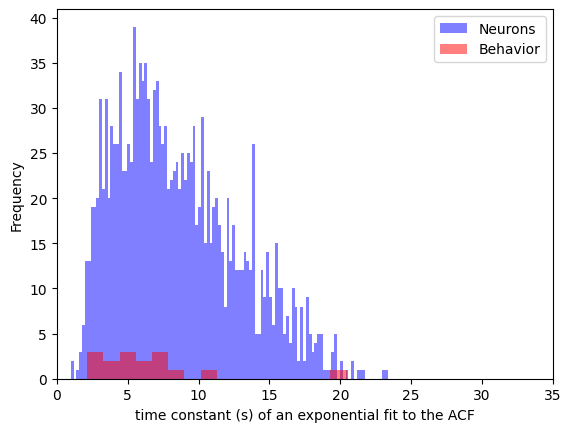

In [11]:
plt.hist(tau_series, bins=112, label='Neurons', color=(0, 0, 1, 0.5))
plt.hist(tau_series_mark, bins=markers_zs.shape[1], label='Behavior', color=(1, 0, 0, 0.5))
plt.xlim(0, 35)
plt.xlabel('time constant (s) of an exponential fit to the ACF')
plt.ylabel('Frequency')
plt.legend()
# plt.savefig(f'{os.path.expanduser('~')}/Desktop/timescale_fly.png', dpi=300)

In [12]:
def r2_score_oos(y_eval, y_pred, baseline):
	ss_res = np.sum((y_eval - y_pred) ** 2, axis=0)
	ss_tot = np.sum((y_eval - baseline) ** 2, axis=0)
	return np.where(ss_tot > 0.0, 1.0 - ss_res / ss_tot, 0.0)

def r2_score_ind(y, y_pred):
	ss_res = np.sum((y - y_pred) ** 2, axis=0)
	ss_tot = np.sum((y - y.mean()) ** 2, axis=0)
	return np.where(ss_tot > 0.0, 1.0 - ss_res / ss_tot, 0.0)

In [44]:
scaler = StandardScaler(with_std=False)
traces_residual_zs = scaler.fit_transform(traces_residual.values)

lr = LinearRegression(fit_intercept=False)


# train-test
X_train, X_test, Y_train, Y_test = train_test_split(
    markers, traces_residual_zs, test_size=0.2, random_state=42
)

lr.fit(X_train, Y_train)
Y_test_pred = lr.predict(X_test)

r2 = r2_score_oos(Y_test, Y_test_pred, Y_train.mean(axis=0)).reshape(-1, 1).T
r2_mean = np.mean(r2.T)

traces_residual_pred = pd.DataFrame(data=scaler.inverse_transform(lr.predict(markers)), columns=traces_residual.columns)


# no train-test
# lr.fit(markers, traces_residual_zs)
# y_pred = lr.predict(markers)
# r2 = r2_score_ind(traces_residual_zs, y_pred).reshape(-1, 1).T
# r2_mean = np.mean(r2.T)
#
# traces_residual_pred = pd.DataFrame(data=scaler.inverse_transform(lr.predict(markers)), columns=traces_residual.columns)

In [45]:
print(r2_mean)
pd.DataFrame(r2).head()


0.035327813234418956


,0,1,2,3,4,5,6,7,8,9,...,1549,1550,1551,1552,1553,1554,1555,1556,1557,1558
0,0.044092,0.035391,0.049613,0.032801,0.027212,0.043664,0.059663,0.041435,0.044964,0.053312,...,0.018562,0.032197,0.030859,0.01697,0.023173,0.027669,0.022739,0.039397,0.017109,0.033017


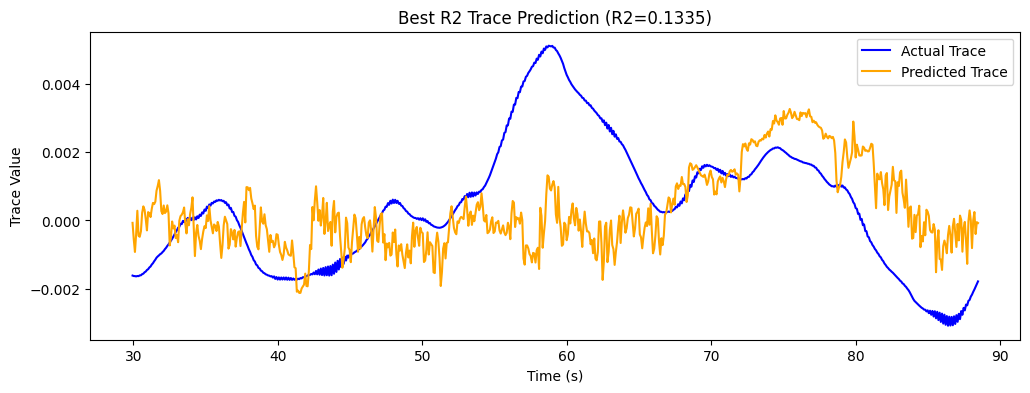

In [46]:
# plot best r2 trace prediction and actual trace
max_x = int(60 * sampling_rate)
best_trace_id = int(np.argmax(r2))
plt.figure(figsize=(12, 4))
plt.plot(timestamps[:max_x], traces_residual.iloc[:max_x, best_trace_id], label='Actual Trace', color='blue')
plt.plot(timestamps[:max_x], traces_residual_pred.iloc[:max_x, best_trace_id], label='Predicted Trace', color='orange')
plt.title(f'Best R2 Trace Prediction (R2={r2[0, best_trace]:.4f})')
plt.xlabel('Time (s)')
plt.ylabel('Trace Value')
plt.legend()
plt.show()